# 04. Inverse problem: recovering the diffusivity from probe measurements

Notebooks 02 and 03 were *forward* problems: given the physics and the boundary drive, predict the field. This notebook runs it backwards, which is the situation in a real experiment. A coil drives a field into a conductor, a few probes record b at fixed positions, and the question is **how fast the field diffuses**: what is the magnetic diffusivity η = 1/(μ₀σ), and therefore the conductivity σ?

**The question this notebook answers:** can a PINN recover η from sparse, noisy probe data, how accurately, and how does that depend on the noise level and on where the probes are?

**Setup.** The equation is b_t = θ b_ξξ, with the time unit fixed by a reference diffusivity η_ref (t = η_ref t_phys / L²), so the unknown is the dimensionless ratio θ = η / η_ref. In notebooks 01 to 03 the time variable was rescaled by η itself, which hides η; here it is kept explicit. The boundary drive is the smooth ramp from problem R, g(t) over 0.05 reference time units, applied at ξ = 0, with b = 0 at ξ = 1 and zero initial field. The network uses the hard-constraint form that worked best in notebook 03.

**The test.** The simulated truth is θ = 0.6, and the PINN always starts from θ = 1 (67% too high). Probe data is the exact solution at the probe positions at 20 equally spaced times in (0, 0.5], plus Gaussian noise of standard deviation σ in units of the field scale B₀ (so σ = 0.01 means 1%).

**How it is judged.** A PINN's answer is only meaningful next to something independent. Two references are used: (1) classical nonlinear least squares on the exact forward model, the standard method; (2) the Cramér–Rao bound, the smallest scatter any unbiased method could achieve with that data. If the PINN does about as well as least squares, it is extracting what the data contain.

**Reading this notebook.** The PINN results come from 28 training runs (3 noise draws per case). The least-squares and Cramér–Rao numbers use 200 draws per case. The caveats are collected at the end.

In [1]:
import os, pickle, time
import numpy as np
import torch
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
torch.set_num_threads(1)
FORCE_RERUN = False      # True: retrain every PINN run below (about 5 minutes each, ~2.5 hours in all)

## 1. Forward model and probe data

The code below is everything this notebook needs: a reference forward model (no neural network), the classical least-squares fit, and the PINN inverse solver. The reference forward model is the Duhamel integral from notebook 03, now with the diffusivity ratio θ as an argument.

In [2]:
import time
import numpy as np
import torch
import torch.nn as nn
from scipy.optimize import least_squares
from scipy.special import erfc

TAU_R = 0.05
T_MAX = 0.5

# ---------------------------------------------------------------- forward reference (independent of the PINN)
def g(t, tau_r=TAU_R):
    x = np.clip(np.asarray(t, float) / tau_r, 0.0, 1.0)
    return x**3 * (10 - 15 * x + 6 * x**2)

def gprime(t, tau_r=TAU_R):
    x = np.clip(np.asarray(t, float) / tau_r, 0.0, 1.0)
    return 30 * x**2 * (1 - x)**2 / tau_r * ((t > 0) & (t < tau_r))

def bA(xi, u, kmax=30):
    xi = np.asarray(xi, float); u = np.asarray(u, float)
    s = 2 * np.sqrt(u)
    out = np.zeros(np.broadcast(xi, u).shape)
    for k in range(kmax):
        out = out + erfc((2 * k + xi) / s) - erfc((2 * k + 2 - xi) / s)
    return out

_GL = np.polynomial.legendre.leggauss(300)

def forward(xi, t, theta, tau_r=TAU_R):
    """b(xi_i, t_i; theta) for paired arrays xi, t: Duhamel integral of the ramp against the step solution."""
    xi = np.atleast_1d(np.asarray(xi, float)); t = np.atleast_1d(np.asarray(t, float))
    xi, t = np.broadcast_arrays(xi, t)
    x, w = _GL
    out = np.zeros(t.shape)
    for i in range(t.size):
        T = min(t.flat[i], tau_r)
        s = 0.5 * T * (x + 1); ws = 0.5 * T * w
        u = np.maximum(theta * (t.flat[i] - s), 1e-300)
        out.flat[i] = (ws * gprime(s, tau_r)) @ bA(xi.flat[i], u)
    return out

# ---------------------------------------------------------------- synthetic probe data
def make_probes(xi_probes, n_times=20, t_max=T_MAX):
    t = t_max * np.arange(1, n_times + 1) / n_times
    XI, T = np.meshgrid(np.asarray(xi_probes, float), t)       # rows: time, cols: probe
    return XI.ravel(), T.ravel()

def synth(xi_d, t_d, theta_true, sigma, rng):
    clean = forward(xi_d, t_d, theta_true)
    return clean, clean + sigma * rng.standard_normal(clean.shape)

# ---------------------------------------------------------------- classical baseline: least squares on the reference model
def ls_fit(xi_d, t_d, y, theta0=1.0):
    """Nonlinear least squares in phi = log theta. Returns theta_hat and the Gauss-Newton standard error of theta
    (sigma_hat / sqrt(J^T J) propagated to theta), with sigma_hat from the residuals."""
    f = lambda p: forward(xi_d, t_d, np.exp(p[0])) - y
    sol = least_squares(f, [np.log(theta0)], xtol=1e-12, ftol=1e-12, gtol=1e-12)
    th = float(np.exp(sol.x[0]))
    J = sol.jac[:, 0]
    dof = max(len(y) - 1, 1)
    s2 = float(sol.fun @ sol.fun) / dof
    se_phi = np.sqrt(s2 / float(J @ J))
    return th, th * se_phi

def crb_theta(xi_d, t_d, theta_true, sigma):
    """Cramer-Rao standard deviation of theta for Gaussian noise sigma at the given probe layout."""
    h = 1e-5
    J = (forward(xi_d, t_d, theta_true * (1 + h)) - forward(xi_d, t_d, theta_true * (1 - h))) / (2 * h * theta_true)
    return sigma / np.sqrt(float(J @ J))

# ---------------------------------------------------------------- PINN
def g_t(t):
    x = torch.clamp(t / TAU_R, 0.0, 1.0)
    return x ** 3 * (10 - 15 * x + 6 * x ** 2)

class MLP(nn.Module):
    def __init__(self, width=64, depth=4):
        super().__init__()
        layers, d_in = [], 2
        for _ in range(depth):
            layers += [nn.Linear(d_in, width), nn.Tanh()]; d_in = width
        layers += [nn.Linear(d_in, 1)]
        self.net = nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m, nn.Linear):
                nn.init.xavier_normal_(m.weight); nn.init.zeros_(m.bias)
    def forward(self, xi, t):
        return self.net(torch.cat([xi, t], 1))

def field(model, xi, t):
    """Hard-constrained: b(0,t)=g(t), b(1,t)=0, b(xi,0)=0 exactly."""
    return g_t(t) * (1 - xi) + xi * (1 - xi) * t * model(xi, t)

def residual(model, xi, t, theta):
    xi = xi.clone().requires_grad_(True); t = t.clone().requires_grad_(True)
    b = field(model, xi, t)
    o = torch.ones_like(b)
    b_t = torch.autograd.grad(b, t, o, create_graph=True)[0]
    b_x = torch.autograd.grad(b, xi, o, create_graph=True)[0]
    b_xx = torch.autograd.grad(b_x, xi, torch.ones_like(b_x), create_graph=True)[0]
    return b_t - theta * b_xx

class InverseRun:
    """Joint training of the network and log-theta from probe data: Adam stage, then staged L-BFGS."""

    def __init__(self, xi_d, t_d, y, seed=0, dtype=torch.float32, phi0=0.0, n_f=2048, n_f_lbfgs=8192):
        self.dtype, self.n_f, self.n_f_lbfgs = dtype, n_f, n_f_lbfgs
        torch.manual_seed(seed)
        self.gen = torch.Generator().manual_seed(seed)
        self.model = MLP().to(dtype)
        self.phi = torch.tensor([phi0], dtype=dtype, requires_grad=True)
        self.xd = torch.tensor(np.asarray(xi_d).reshape(-1, 1), dtype=dtype)
        self.td = torch.tensor(np.asarray(t_d).reshape(-1, 1), dtype=dtype)
        self.yd = torch.tensor(np.asarray(y).reshape(-1, 1), dtype=dtype)
        self.hist = dict(step=[], theta=[], pde=[], data=[], phase=[], lam=[])
        self.step = 0
        self.t0 = time.perf_counter()

    def pts(self, n):
        return (torch.rand(n, 1, generator=self.gen, dtype=self.dtype),
                T_MAX * torch.rand(n, 1, generator=self.gen, dtype=self.dtype))

    def terms(self, xf, tf):
        r = residual(self.model, xf, tf, torch.exp(self.phi))
        return (r ** 2).mean(), ((field(self.model, self.xd, self.td) - self.yd) ** 2).mean()

    def _log(self, pde, data, phase, lam):
        h = self.hist
        h["step"].append(self.step); h["theta"].append(float(torch.exp(self.phi).detach()))
        h["pde"].append(float(pde)); h["data"].append(float(data)); h["phase"].append(phase); h["lam"].append(lam)

    def adam(self, n_steps, lam0, lam1, lr=1e-3, lr_phi=2e-3, log_every=100):
        opt = torch.optim.Adam([dict(params=self.model.parameters(), lr=lr), dict(params=[self.phi], lr=lr_phi)])
        sched = torch.optim.lr_scheduler.ExponentialLR(opt, gamma=(1e-2) ** (1.0 / max(n_steps, 1)))
        for k in range(n_steps):
            xf, tf = self.pts(self.n_f)
            pde, data = self.terms(xf, tf)
            lam = lam0 * (lam1 / lam0) ** (k / max(n_steps - 1, 1))
            loss = pde + lam * data
            opt.zero_grad(); loss.backward(); opt.step(); sched.step(); self.step += 1
            if k % log_every == 0:
                self._log(pde.detach(), data.detach(), "adam", lam)

    def lbfgs(self, n_iter, lam, theta_free=True):
        xf, tf = self.pts(self.n_f_lbfgs)
        params = list(self.model.parameters()) + ([self.phi] if theta_free else [])
        lb = torch.optim.LBFGS(params, lr=1.0, max_iter=25, history_size=50, tolerance_grad=1e-14,
                               tolerance_change=1e-16, line_search_fn="strong_wolfe")
        last = {}
        def closure():
            lb.zero_grad()
            pde, data = self.terms(xf, tf)
            loss = pde + lam * data
            loss.backward(); last["t"] = (float(pde), float(data))
            return loss
        for _ in range(n_iter // 25):
            lb.step(closure); self.step += 25
            self._log(last["t"][0], last["t"][1], "lbfgs", lam)

    def result(self):
        h = self.hist
        return dict(theta=float(torch.exp(self.phi).detach()), wall_s=time.perf_counter() - self.t0, hist=h,
                    pde=h["pde"][-1], data=h["data"][-1])

In [3]:
THETA_TRUE = 0.6
LAYOUTS = {"p3": [0.2, 0.5, 0.8], "p1_0.1": [0.1], "p1_0.3": [0.3], "p1_0.5": [0.5], "p1_0.8": [0.8],
           "p5": [0.1, 0.3, 0.5, 0.7, 0.9]}
CFG = dict(n_adam=3000, lam_adam=(1000.0, 100.0), lbfgs_stages=((700, 1000.0), (700, 300.0), (700, 100.0)), lr_phi=2e-3)

def run_job(xd, td, y, seed, cfg=CFG):
    run = InverseRun(xd, td, y, seed=seed)
    run.adam(cfg["n_adam"], *cfg["lam_adam"], lr_phi=cfg["lr_phi"])
    for n_it, lam in cfg["lbfgs_stages"]:
        run.lbfgs(n_it, lam)
    return run.result()

def data_for(layout, sigma, r):
    xd, td = make_probes(LAYOUTS[layout])
    clean = forward(xd, td, THETA_TRUE)
    y = clean + sigma * np.random.default_rng(100 + r).standard_normal(clean.shape)
    return xd, td, clean, y

### Checking the forward model

Two independent checks: at θ = 1 it must reproduce the stored reference for problem R from notebook 03, and at θ = 0.6 it must agree with a finite-difference solution of b_t = θ b_ξξ. The finite-difference run uses the rescaling τ = θt, under which the PDE becomes b_τ = b_ξξ and the ramp lasts θ × 0.05.

In [4]:
from scipy.linalg import solve_banded
ref = np.load("../data/reference_fields.npz"); xi_g, tau_g = ref["xi"], ref["tau"]
R1 = forward(xi_g[[40, 100, 160]][:, None], tau_g[[20, 60, 100, 180]][None, :], 1.0)
stored = np.load("../data/ref_R.npy") if os.path.exists("../data/ref_R.npy") else None
print("stored R reference available:", stored is not None)

def fd_theta(theta, N=800, nsteps=8000):
    """Crank-Nicolson FD for b_t = theta b_xixi with the ramp drive, via tau = theta t."""
    tr = TAU_R * theta; tend = T_MAX * theta
    h = 1.0 / N; dt = tend / nsteps; r = dt / h**2; n = N - 1
    ab = np.zeros((3, n)); ab[0, 1:] = -r / 2; ab[1] = 1 + r; ab[2, :-1] = -r / 2
    b = np.zeros(N + 1); hist = [b.copy()]
    for k in range(nsteps):
        t1 = (k + 1) * dt
        rhs = (1 - r) * b[1:N] + r / 2 * (b[0:N - 1] + b[2:N + 1]); rhs[0] += r / 2 * g(t1, tr)
        b[0] = g(t1, tr); b[1:N] = solve_banded((1, 1), ab, rhs); hist.append(b.copy())
    return np.array(hist)

H = fd_theta(THETA_TRUE); xs = np.linspace(0, 1, 801)
errs = []
for x, t in [(0.1, 0.05), (0.2, 0.1), (0.5, 0.3), (0.7, 0.5), (0.8, 0.25)]:
    k = int(round(t / T_MAX * 8000))
    errs.append(abs(forward(x, t, THETA_TRUE)[0] - np.interp(x, xs, H[k])))
print("forward model vs finite differences at theta = 0.6, max abs difference over 5 points:", f"{max(errs):.1e}")
if stored is not None:
    j = [20, 60, 100, 180]; i = [40, 100, 160]
    d = max(abs(forward(xi_g[a], tau_g[b], 1.0)[0] - stored[b, a]) for a in i for b in j)
    print("forward model at theta = 1 vs stored R reference:", f"{d:.1e}")

stored R reference available: True


forward model vs finite differences at theta = 0.6, max abs difference over 5 points: 5.0e-07
forward model at theta = 1 vs stored R reference: 2.0e-15


### The probe data

Left: the three probe signals at ξ = 0.2, 0.5 and 0.8, with 1% noise. The probe near the driven edge rises quickly and saturates; the far probe responds late and weakly. Right: how the middle probe's curve changes with θ. The effect of θ is mostly on *timing* (how soon the field arrives) and on how fast it approaches its final value, and that is the information the inversion uses. A larger θ means faster penetration.

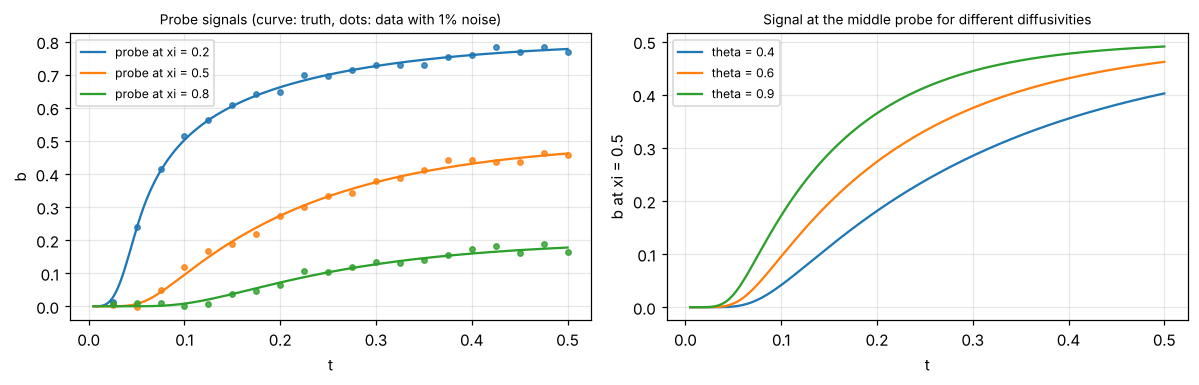

In [5]:
xd, td, clean, y1 = data_for("p3", 0.01, 0)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
tt = np.linspace(0.005, T_MAX, 200)
for j, xp in enumerate(LAYOUTS["p3"]):
    ax[0].plot(tt, forward(xp, tt, THETA_TRUE), color=f"C{j}", label=f"probe at xi = {xp}")
    m = xd == xp
    ax[0].plot(td[m], y1[m], "o", color=f"C{j}", ms=3.5, alpha=0.8)
ax[0].set_xlabel("t"); ax[0].set_ylabel("b"); ax[0].set_title("Probe signals (curve: truth, dots: data with 1% noise)", fontsize=9)
ax[0].legend(fontsize=8)
for th in (0.4, 0.6, 0.9):
    ax[1].plot(tt, forward(0.5, tt, th), label=f"theta = {th}")
ax[1].set_xlabel("t"); ax[1].set_ylabel("b at xi = 0.5"); ax[1].set_title("Signal at the middle probe for different diffusivities", fontsize=9); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 2. The classical baseline and its statistical limit

Before any neural network: fit θ by nonlinear least squares against the reference forward model. This is the standard method, it uses the exact solution, and it gives the estimate the PINN should be compared with. The **Cramér–Rao bound** is the smallest standard deviation any unbiased estimator can reach for a given layout and noise level, so it separates "the PINN is imprecise" from "the data can't do better". The Monte Carlo below repeats the fit on 200 independent noise draws per case.

In [6]:
LS_PATH = "../results/m4_ls.pkl"
def ls_monte_carlo(layout, sigma, n=200):
    xd, td = make_probes(LAYOUTS[layout]); clean = forward(xd, td, THETA_TRUE)
    th = np.array([ls_fit(xd, td, clean + sigma * np.random.default_rng(1000 + r).standard_normal(clean.shape))[0] for r in range(n)])
    return th
CASES = [("p3", s) for s in (0.005, 0.01, 0.02, 0.05)] + [(l, 0.01) for l in ("p1_0.1", "p1_0.3", "p1_0.5", "p1_0.8", "p5")]
if os.path.exists(LS_PATH) and not FORCE_RERUN:
    LS = pickle.load(open(LS_PATH, "rb"))
else:
    LS = {c: ls_monte_carlo(*c) for c in CASES}; pickle.dump(LS, open(LS_PATH, "wb"))
CRB = {c: crb_theta(*make_probes(LAYOUTS[c[0]]), THETA_TRUE, c[1]) for c in CASES}
print(f"true theta = {THETA_TRUE}; 200 noise draws per case")
print(f"{'layout':8s} {'sigma':>6s} {'LS mean':>9s} {'LS std':>9s} {'CRB std':>9s} {'LS std/CRB':>11s}")
for c in CASES:
    print(f"{c[0]:8s} {c[1]:6.3f} {LS[c].mean():9.4f} {LS[c].std(ddof=1):9.4f} {CRB[c]:9.4f} {LS[c].std(ddof=1)/CRB[c]:11.2f}")

true theta = 0.6; 200 noise draws per case
layout    sigma   LS mean    LS std   CRB std  LS std/CRB
p3        0.005    0.6000    0.0029    0.0028        1.05
p3        0.010    0.6000    0.0058    0.0055        1.05
p3        0.020    0.6000    0.0116    0.0111        1.05
p3        0.050    0.6006    0.0288    0.0277        1.04
p1_0.1    0.010    0.6007    0.0137    0.0149        0.92
p1_0.3    0.010    0.6002    0.0076    0.0078        0.97
p1_0.5    0.010    0.6001    0.0074    0.0077        0.96
p1_0.8    0.010    0.6002    0.0145    0.0151        0.96
p5        0.010    0.6002    0.0046    0.0046        1.01


## 3. The PINN inverse solver

The network b(ξ, t) has the exact boundary and initial conditions built in, as in notebook 03. The unknown is φ = log θ, trained jointly with the network weights. The loss is the PDE residual (using the current θ) plus λ times the mean squared mismatch to the probe data. Notes on the training schedule (it is the part that needed care):

- Adam for 3000 steps with λ decreasing smoothly from 1000 to 100, then L-BFGS in three stages (700 iterations each) with λ = 1000, 300, 100. A large λ early lets the network find the data before the physics has a say; the physics weight is raised later.
- A first version used one L-BFGS stage at the final λ. It **diverged on all three noisy cases it completed** (θ ran off to hundreds and the network collapsed; the noise-free case was fine). Stepping λ down gradually fixed it. That schedule was chosen after seeing the failure, on the 3-probe, 1% noise case.
- The same schedule is used at every noise level and layout, not tuned per case.

Each run takes about 5 minutes on one CPU core. The table lists every run next to least squares on the *same* noisy data.

In [7]:
RUNS = {}
for k in (0, 1):
    p = f"../results/m4_{k}.pkl"
    if os.path.exists(p): RUNS.update(pickle.load(open(p, "rb")))
print(len(RUNS), "PINN inverse runs loaded")

def pinn_vs_ls(job):
    layout, sigma, r = job
    xd, td, clean, y = data_for(layout, sigma, r)
    th_ls, se_ls = ls_fit(xd, td, y) if sigma > 0 else (THETA_TRUE, 0.0)
    return RUNS[job]["theta"], th_ls, se_ls

print(f"{'layout':8s} {'sigma':>6s} {'seed':>4s} {'PINN theta':>11s} {'LS theta':>9s} {'PINN err %':>11s} {'LS err %':>9s} {'|PINN-LS| / CRB':>16s}")
for job in sorted(RUNS, key=lambda j: (j[0] != "p3", j[0], j[1], j[2])):
    th, th_ls, se = pinn_vs_ls(job)
    crb = crb_theta(*make_probes(LAYOUTS[job[0]]), THETA_TRUE, job[1]) if job[1] > 0 else np.nan
    print(f"{job[0]:8s} {job[1]:6.3f} {job[2]:4d} {th:11.4f} {th_ls:9.4f} {100*(th-THETA_TRUE)/THETA_TRUE:11.2f} {100*(th_ls-THETA_TRUE)/THETA_TRUE:9.2f} {abs(th-th_ls)/crb:16.2f}")

28 PINN inverse runs loaded
layout    sigma seed  PINN theta  LS theta  PINN err %  LS err %  |PINN-LS| / CRB
p3        0.000    0      0.6004    0.6000        0.06      0.00              nan


p3        0.005    0      0.6038    0.6022        0.63      0.36             0.59


p3        0.005    1      0.6015    0.6009        0.25      0.15             0.20


p3        0.005    2      0.6025    0.6017        0.42      0.28             0.31


p3        0.010    0      0.6062    0.6043        1.04      0.72             0.34


p3        0.010    1      0.6024    0.6018        0.40      0.30             0.11


... (6 outputs left out)

p1_0.8    0.010    1      0.6086    0.6050        1.43      0.84             0.23
p1_0.8    0.010    2      0.6073    0.6086        1.21      1.43             0.09


p5        0.010    0      0.6023    0.6026        0.38      0.44             0.07


p5        0.010    1      0.6056    0.6050        0.94      0.83             0.14


p5        0.010    2      0.5984    0.5968       -0.27     -0.53             0.34


### Summary over noise realizations

For each case: the RMS error of the PINN estimate across its three noise realizations, the RMS error of least squares on the *same* three data sets, and the Cramér–Rao standard deviation. With three realizations these RMS values are rough (a standard deviation estimated from three points is uncertain by about 50%), so the table is for orders of magnitude and trends, not fine comparisons.

In [8]:
def rms(a): a = np.asarray(a); return float(np.sqrt(np.mean(a ** 2)))
rows = []
cases_p = [("p3", s) for s in (0.005, 0.01, 0.02, 0.05)] + [(l, 0.01) for l in ("p1_0.1", "p1_0.3", "p1_0.5", "p1_0.8", "p5")]
print(f"{'layout':8s} {'sigma':>6s} {'n':>2s} {'PINN rms err':>13s} {'LS rms err':>11s} {'CRB std':>9s} {'PINN rms / CRB':>15s}")
SUMMARY = {}
for c in cases_p:
    jobs = [j for j in RUNS if j[0] == c[0] and j[1] == c[1]]
    if not jobs: continue
    e_p = [RUNS[j]["theta"] - THETA_TRUE for j in jobs]
    e_l = [pinn_vs_ls(j)[1] - THETA_TRUE for j in jobs]
    SUMMARY[c] = (rms(e_p), rms(e_l), CRB[c], len(jobs))
    print(f"{c[0]:8s} {c[1]:6.3f} {len(jobs):2d} {rms(e_p):13.4f} {rms(e_l):11.4f} {CRB[c]:9.4f} {rms(e_p)/CRB[c]:15.2f}")
j0 = ("p3", 0.0, 0)
if j0 in RUNS: print(f"\nNoise-free (3 probes): PINN theta = {RUNS[j0]['theta']:.5f}, error {100*(RUNS[j0]['theta']-THETA_TRUE)/THETA_TRUE:.3f}%")

layout    sigma  n  PINN rms err  LS rms err   CRB std  PINN rms / CRB


p3        0.005  3        0.0028      0.0017    0.0028            1.00


p3        0.010  3        0.0048      0.0034    0.0055            0.87


p3        0.020  3        0.0094      0.0068    0.0111            0.85


p3        0.050  3        0.0212      0.0172    0.0277            0.77


p1_0.1    0.010  3        0.0198      0.0179    0.0149            1.33


p1_0.3    0.010  3        0.0094      0.0086    0.0078            1.20


p1_0.5    0.010  3        0.0106      0.0079    0.0077            1.38


p1_0.8    0.010  3        0.0168      0.0147    0.0151            1.11


p5        0.010  3        0.0036      0.0037    0.0046            0.79

Noise-free (3 probes): PINN theta = 0.60037, error 0.062%


### How close is the PINN to the least-squares answer on the same data?

This is the cleaner comparison than RMS errors from three draws. Both methods see identical noisy data, so their *difference* isolates the PINN's own error. It is expressed in units of the Cramér–Rao standard deviation for that case (1.0 would mean the PINN differs from least squares by as much as the statistical noise itself).

In [9]:
diffs, ratios, per_case = [], [], {}
for job in RUNS:
    if job[1] == 0: continue
    th, th_ls, _ = pinn_vs_ls(job)
    crb = CRB[(job[0], job[1])]
    diffs.append(th - th_ls); ratios.append((th - th_ls) / crb)
    per_case.setdefault((job[0], job[1]), []).append(th - th_ls)
diffs, ratios = np.array(diffs), np.array(ratios)
print(f"{len(diffs)} noisy runs: mean(PINN - LS) = {diffs.mean():+.4f}  (std {diffs.std(ddof=1):.4f}); PINN above LS in {(diffs > 0).sum()} of {len(diffs)}")
print(f"|PINN - LS| / CRB: median {np.median(np.abs(ratios)):.2f}, 90th percentile {np.percentile(np.abs(ratios), 90):.2f}, max {np.abs(ratios).max():.2f}")
print(f"mean(PINN - LS) in percent of true theta: {100*diffs.mean()/THETA_TRUE:+.2f}%")

27 noisy runs: mean(PINN - LS) = +0.0016  (std 0.0021); PINN above LS in 23 of 27
|PINN - LS| / CRB: median 0.20, 90th percentile 0.39, max 0.87
mean(PINN - LS) in percent of true theta: +0.27%


### Which probe positions carry the most information?

The Cramér–Rao standard deviation depends on how many measurements there are as well as where. In the layouts above a single probe has 20 data points, three probes 60 and five probes 100. Multiplying the bound by the square root of the number of data points gives a per-measurement figure that compares positions on equal terms (smaller is better: that position is more informative per measurement).

In [10]:
print(f"{'layout':8s} {'n data':>7s} {'CRB std (1%)':>13s} {'CRB x sqrt(n)':>14s}")
for n in ("p1_0.1", "p1_0.3", "p1_0.5", "p1_0.8", "p3", "p5"):
    nd = len(make_probes(LAYOUTS[n])[0])
    print(f"{n:8s} {nd:7d} {CRB[(n, 0.01)]:13.4f} {CRB[(n, 0.01)] * np.sqrt(nd):14.4f}")

layout    n data  CRB std (1%)  CRB x sqrt(n)
p1_0.1        20        0.0149         0.0665
p1_0.3        20        0.0078         0.0351
p1_0.5        20        0.0077         0.0344
p1_0.8        20        0.0151         0.0676
p3            60        0.0055         0.0429
p5           100        0.0046         0.0458


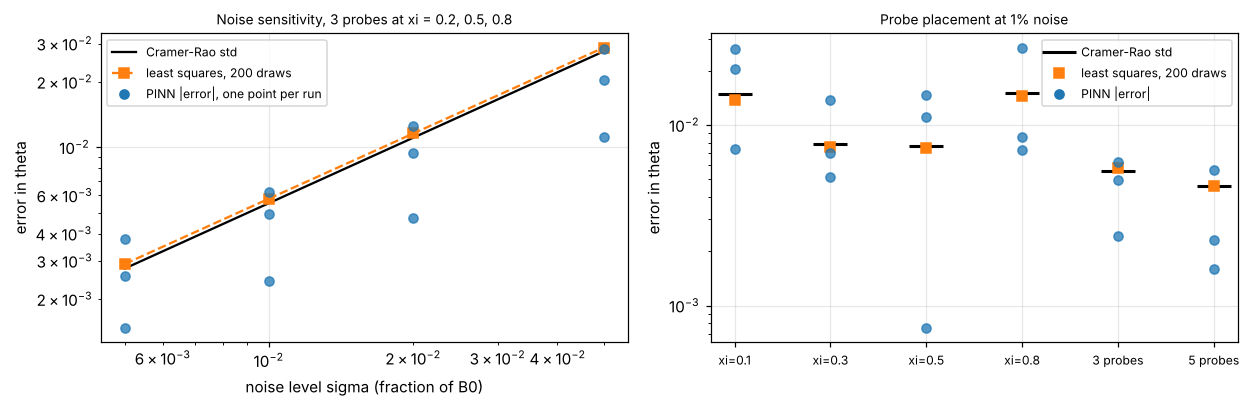

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8))
sig = [0.005, 0.01, 0.02, 0.05]
ax[0].loglog(sig, [CRB[("p3", s)] for s in sig], "k-", lw=1.5, label="Cramer-Rao std")
ax[0].loglog(sig, [LS[("p3", s)].std(ddof=1) for s in sig], "s--", color="C1", label="least squares, 200 draws")
for s in sig:
    for j in [j for j in RUNS if j[0] == "p3" and j[1] == s]:
        ax[0].loglog([s], [abs(RUNS[j]["theta"] - THETA_TRUE)], "o", color="C0", alpha=0.75)
ax[0].loglog([], [], "o", color="C0", label="PINN |error|, one point per run")
ax[0].set_xlabel("noise level sigma (fraction of B0)"); ax[0].set_ylabel("error in theta"); ax[0].legend(fontsize=8)
ax[0].set_title("Noise sensitivity, 3 probes at xi = 0.2, 0.5, 0.8", fontsize=9)
names = ["p1_0.1", "p1_0.3", "p1_0.5", "p1_0.8", "p3", "p5"]
xs_ = np.arange(len(names))
ax[1].semilogy(xs_, [CRB[(n, 0.01)] for n in names], "k_", ms=22, mew=2, label="Cramer-Rao std")
ax[1].semilogy(xs_, [LS[(n, 0.01)].std(ddof=1) for n in names], "s", color="C1", label="least squares, 200 draws")
for i_, n in enumerate(names):
    for j in [j for j in RUNS if j[0] == n and j[1] == 0.01]:
        ax[1].semilogy([i_], [abs(RUNS[j]["theta"] - THETA_TRUE)], "o", color="C0", alpha=0.75)
ax[1].semilogy([], [], "o", color="C0", label="PINN |error|")
ax[1].set_xticks(xs_); ax[1].set_xticklabels(["xi=0.1", "xi=0.3", "xi=0.5", "xi=0.8", "3 probes", "5 probes"], fontsize=8)
ax[1].set_ylabel("error in theta"); ax[1].set_title("Probe placement at 1% noise", fontsize=9); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

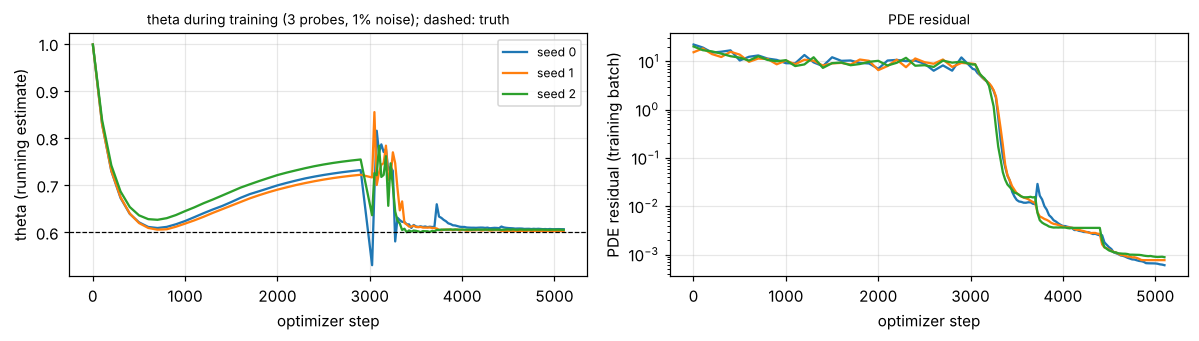

In [12]:
# training trace: how theta converges, for the default 3-probe case at 1% noise
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for j in [j for j in RUNS if j[0] == "p3" and j[1] == 0.01]:
    h = RUNS[j]["hist"]; ax[0].plot(h["step"], h["theta"], label=f"seed {j[2]}")
ax[0].axhline(THETA_TRUE, color="k", lw=0.8, ls="--"); ax[0].set_xlabel("optimizer step"); ax[0].set_ylabel("theta (running estimate)")
ax[0].set_title("theta during training (3 probes, 1% noise); dashed: truth", fontsize=9); ax[0].legend(fontsize=8)
for j in [j for j in RUNS if j[0] == "p3" and j[1] == 0.01]:
    h = RUNS[j]["hist"]; ax[1].semilogy(h["step"], h["pde"], label=f"seed {j[2]}")
ax[1].set_xlabel("optimizer step"); ax[1].set_ylabel("PDE residual (training batch)"); ax[1].set_title("PDE residual", fontsize=9)
plt.tight_layout(); plt.show()

## 4. What the results say

**The baseline is sound.** Least squares on the exact model is unbiased (mean θ̂ = 0.600 in every case over 200 draws) and its scatter is within 8% of the Cramér–Rao bound (ratio 0.92 to 1.05). So the bound is a reliable yardstick: it says how well *anyone* can do with this data.

**Noise sensitivity.** The statistical limit on θ is proportional to the noise level. With the three-probe layout it is 0.0028, 0.0055, 0.011 and 0.028 at σ = 0.5%, 1%, 2% and 5%, which is 0.5% to 4.6% of θ. With noise-free data the PINN recovers θ = 0.6004, an error of 0.06%, so the PINN's own error floor is far below the noise-limited error at any of these noise levels. At the noisy levels the PINN's errors follow the same straight line on the log–log plot as least squares.

**The PINN's answer is close to least squares.** Across the 27 noisy runs the difference between the PINN and least squares on the same data has a median size of 0.20 Cramér–Rao standard deviations, a 90th percentile of 0.39 and a worst case of 0.87. So most of the PINN's error is the noise in the data, not the network. It also has a small systematic offset: it came out above least squares in 23 of 27 runs, by +0.0016 on average (+0.27% of θ). My reading is that this comes from the PDE being enforced softly (final residual about 1e-3, against about 2e-4 in the forward problem in notebook 03), so the network trades a little physics for fit. I have not run the experiment that would confirm this, such as a longer final stage or a larger final PDE weight.

**Probe placement.** The bound at 1% noise is 0.0149 for a single probe at ξ = 0.1, 0.0078 at 0.3, 0.0077 at 0.5, 0.0151 at 0.8, 0.0055 for the three-probe layout and 0.0046 for five probes. Layouts with more probes also have more data points (20 per probe), so a fairer comparison is the bound multiplied by √(number of data points): 0.066, 0.035, 0.034, 0.068, 0.043 and 0.046. By that measure a probe in the interior (ξ = 0.3 to 0.5) is about twice as informative per measurement as one near the driven edge (0.1) or near the far wall (0.8), and spreading probes over several positions did not beat one well-placed probe measurement for measurement. A plausible reason is that the signal near the drive is dominated by the (known) ramp and the signal at the far end is small and late, but this is an interpretation I did not test. The PINN follows least squares at every layout, with its errors scattered around the bound in the same way.

**What the training trace shows.** During the Adam stage the PDE residual stays near 10 (the data term dominates because of the large λ) and θ drifts to about 0.7. The physics is only enforced in the L-BFGS stages, where the residual drops to about 1e-3 and θ settles near the truth. So this is closer to "fit the data with a network, then bring it into agreement with the PDE" than a gradual joint solve.

## 5. Summary and caveats

**M4 status.** The diffusivity ratio is recovered with the error and its sensitivities reported. With three probes and 1% noise the PINN recovered θ within 0.4% to 1.0% of the true value in the three runs (0.6024 to 0.6062 for a true 0.6), consistent with the statistical limit of 0.9%. Noise-free recovery is 0.06%. The PINN's error is dominated by measurement noise and matches the classical least-squares error to within about 0.2 standard deviations (median), with a small systematic offset of about +0.3%.

**What this does and does not show.**

- The PINN is *not* better than least squares here. The forward model is exactly known and cheap, so classical fitting is the right tool. The PINN's value would be for cases without a fast exact forward model, which this problem does not test.
- The forward model is exact and the boundary drive g(t) is known perfectly. Real data would have drive uncertainty, probe position error and unmodelled physics. None of that is tested.
- One true value (θ = 0.6) and one starting guess (θ = 1) were used. Behavior at other values, or from a worse starting guess, is unknown.
- Each PINN case has three noise draws. That is enough to see that the PINN tracks least squares, not enough to measure its bias precisely.
- The training schedule was developed on the 3-probe, 1% noise case, so that case is not independent of the tuning. The first schedule I tried diverged, and the version here was chosen after seeing it.
- The probe times are 20 equally spaced samples on (0, 0.5], the same for every probe. Layout comparisons are at that sampling only.
- Noise is Gaussian with the same σ at every sample, which is the case the Cramér–Rao bound assumes.

**Physical units.** θ = η / η_ref, so a recovered θ converts to η = θ η_ref once the reference diffusivity (set by the choice of length L and time scale) is fixed; the conductivity follows from σ = 1/(μ₀η).

**Next:** M5, the repository structure: refactor the three forward notebooks and this one into an installable package with tests (analytic solutions, finite-difference convergence, a fast PINN smoke test, and a check that the inverse recovers θ on noise-free data).